In [28]:
# These are the libraries you may use for this assignment.
# If you would like to use any other libraries, email james@uwaterloo.ca for permission first.
# Generative AI tools (including coding assistants) are not permitted for this assignment.

from IPython.display import display, Math, Latex

import pandas as pd
import numpy as np
import numpy_financial as npf
import yfinance as yf
import matplotlib.pyplot as plt
import random
from datetime import datetime
import math

## CFM 101 — Group Assignment 2026
### Robo-Advising Challenge: Two Clients, Two Strategies

**Team Number:** XX  
**Team Member Names (three or four):**  

Enter the names of all participating members below (one name per line):

**Submission:** Friday, November 27, 2026, at 9:00 AM (Eastern), via Dropbox.  
**Submit this completed Jupyter notebook only.**

Your team must construct **both** portfolios from the supplied `Tickers.csv` file:

- **Client A — Growth:** $\$1,000,000$ CAD; seek the highest expected return.
- **Client B — Low Risk:** $\$750,000$ CAD; seek the lowest portfolio volatility.

Both clients require 10–20 eligible stocks, at most 15% in any stock and at most 40% in any sector. Read the full assignment handout for all eligibility, fee, currency, and competition rules. Do not hardcode the selected stocks. Check that tickers are valid. The supplied ticker universe will permit feasible portfolios.

**No generative AI may be used in preparing this assignment.**

## CFM 101 — Group Assignment 2026
### Robo-Advising Challenge: Two Clients, Two Strategies

**Team Number:** XX  
**Team Member Names (three or four):**  

Enter the names of all participating members below (one name per line):

**Submission:** Friday, November 27, 2026, at 9:00 AM (Eastern), via Dropbox.  
**Submit this completed Jupyter notebook only.**

Your team must construct **both** portfolios from the supplied `Tickers.csv` file:

- **Client A — Growth:** $\$1,000,000$ CAD; seek the highest expected return.
- **Client B — Low Risk:** $\$750,000$ CAD; seek the lowest portfolio volatility.

Both clients require 10–20 eligible stocks, at most 15% in any stock and at most 40% in any sector. Read the full assignment handout for all eligibility, fee, currency, and competition rules. Do not hardcode the selected stocks. Check that tickers are valid. The supplied ticker universe will permit feasible portfolios.

**No generative AI may be used in preparing this assignment.**

## Data preparation and shared functions

Read `Tickers.csv`, check ticker eligibility, retrieve the data needed for your strategies, and create any functions you will reuse for both clients. Use closing prices from **November 27, 2026** for the purchase calculations. All portfolio values and weights must be calculated in CAD, with purchase fees paid from the client budget.

In [29]:
import time  # not in the given import cell; needed for time.sleep

GROUP_NUMBER = "6"        
TICKER_FILE = "Tickers.csv"

PURCHASE_DATE = pd.Timestamp("2026-11-27")
# Competition holding window (used to find earnings reports during the competition)
HOLD_START = pd.Timestamp("2026-11-27 16:00", tz="America/New_York")
HOLD_END   = pd.Timestamp("2026-12-04 16:00", tz="America/New_York")

# Price history to download: must start before the volume window and cover a year of signals
HISTORY_START = pd.Timestamp("2024-10-01")

# Volume rule
VOLUME_START = pd.Timestamp("2025-10-01")
VOLUME_END   = pd.Timestamp("2026-09-30")
MIN_AVG_VOLUME = 5000
MIN_TRADING_DAYS_IN_MONTH = 18

# Client mandates
CLIENT_BUDGETS = {"A": 1_000_000, "B": 750_000}       # CAD
CLIENT_N_STOCKS = {"A": 12, "B": 20}                   # our chosen portfolio sizes
MIN_STOCKS, MAX_STOCKS = 10, 20
MAX_STOCK_WEIGHT = 0.15
MAX_SECTOR_WEIGHT = 0.40

# Transaction fee: the smaller of US$2.15 and US$0.001 per share, for every stock
MAX_FEE_USD = 2.15
FEE_PER_SHARE_USD = 0.001
SAFETY_BUFFER_CAD = 0.01     # leave one cent unspent so rounding can never exceed the budget

# Eligibility (yfinance codes)
ALLOWED_QUOTE_TYPES = ["EQUITY"]
ALLOWED_CURRENCIES  = ["CAD", "USD"]
US_EXCHANGES = ["NMS", "NGM", "NCM", "NYQ", "ASE", "PCX", "BTS"]  # Nasdaq tiers, NYSE, NYSE American, NYSE Arca, Cboe
CA_EXCHANGES = ["TOR", "VAN", "NEO", "CNQ"]                       # TSX, TSX Venture, Cboe Canada, CSE
# OTC / pink-sheet codes are deliberately excluded: they are not exchange listings.
MAX_STALE_DAYS = 5           # last price older than this before the purchase date = not trading

# Strategy parameters
TRADING_DAYS_PER_YEAR = 252
LOOKBACK_DAYS = 252          # one year: Client B volatility and the equal-weight comparison period
MOMENTUM_DAYS = 126          # about six months
SHORT_MOMENTUM_DAYS = 20     # about one month
TREND_DAYS = 50              # 50-day moving average trend filter
CATALYST_BONUS = 0.10        # score bonus for Client A stocks with earnings in the window and positive momentum

BENCHMARK_TICKERS = {"US": "^GSPC", "CA": "^GSPTSE"}  # S&P 500 and S&P/TSX Composite
FX_TICKER = "CAD=X"          # CAD per 1 USD
PAUSE_SECONDS = 0.2          # pause between per-ticker requests to avoid rate limits





## read the ticker file and collect company information

def read_tickers(path):
    """Read the ticker file (one ticker per row, no header) in order to return a clean, de-duplicated list."""
    raw = pd.read_csv(path, header=None) ## pd haven't touched the data
    tickers = (raw.iloc[:, 0].dropna().astype(str)
               .str.strip().str.upper())
    tickers = tickers[tickers != ""].drop_duplicates()
    return list(tickers)


def get_stock_info(tickers):
    """Looking up quote type, exchange, currency and sector for each ticker.
    Tickers that yfinance cannot find will result in empty values (they fail the checks later)."""
    rows = []
    for ticker in tickers:
        try:
            info = yf.Ticker(ticker).info
        except Exception:
            info = {}
        rows.append({
            "Ticker": ticker,
            "SecurityType": info.get("quoteType"),
            "Exchange": info.get("exchange"),
            "Currency": info.get("currency"),
            "Sector": info.get("sector"),
            "Name": info.get("longName") or info.get("shortName"),
        })
        time.sleep(PAUSE_SECONDS)
    return pd.DataFrame(rows).set_index("Ticker")


def market_of(exchange):
    """Return 'US', 'CA' or None depending on where the stock is listed."""
    if pd.isna(exchange):
        return None
    if exchange in US_EXCHANGES:
        return "US"
    if exchange in CA_EXCHANGES:
        return "CA"
    return None



## download price and volume history
#### Use auto_adjust=False and Close column


def download_history(tickers, start, end):
    """Download daily closes and volumes
       return into two DFs (dates x tickers)"""

    data = yf.download(tickers, start=start, end=end + pd.Timedelta(days=1),
                       auto_adjust=False, progress=False, group_by="column")

    closes = data["Close"]
    volumes = data["Volume"]
    # With one ticker yfinance can return a Series; make it a DataFrame either way
    if isinstance(closes, pd.Series):
        closes = closes.to_frame(tickers[0])
        volumes = volumes.to_frame(tickers[0])
    closes.index = pd.to_datetime(closes.index).tz_localize(None)
    volumes.index = pd.to_datetime(volumes.index).tz_localize(None)
    return closes, volumes 



def get_fx_rate(index, start, end):
    """CAD per USD, lined up with the stock dates (forward-filled over holidays)."""
    fx = yf.download(FX_TICKER, start=start, end=end + pd.Timedelta(days=1),
                     auto_adjust=False, progress=False)["Close"]
    if isinstance(fx, pd.DataFrame):
        fx = fx.iloc[:, 0]
    fx.index = pd.to_datetime(fx.index).tz_localize(None)
    return fx.reindex(fx.index.union(index)).ffill().reindex(index).rename("USDCAD")



def convert_to_cad(closes_local, currencies, fx):
    """Multiply USD-quoted columns by the daily exchange rate; CAD columns stay as they are."""
    prices_cad = closes_local.copy()
    for ticker in closes_local.columns:
        if currencies.get(ticker) == "USD":
            prices_cad[ticker] = closes_local[ticker] * fx
    return prices_cad




## Volume Rule
## A "trading day" is a day the stock actually has a volume record. Because TSX and US holidays differ, each stock is counted on its own calendar.
## The average is taken over all remaining days (not an average of monthly averages).


def average_volume(volume_series, start, end, min_days):
    """Average daily volume over [start, end], excluding months with fewer than min_days trading days."""
    v = volume_series.loc[start:end].dropna()
    if v.empty:
        return np.nan
    month = v.index.to_period("M")
    days_per_month = v.groupby(month).count()
    full_months = days_per_month[days_per_month >= min_days].index
    v = v[month.isin(full_months)]
    return v.mean() if not v.empty else np.nan


## Eligibility check + load_stock_data()
def check_eligibility(info, closes_local, volumes, as_of):
    """Add AvgVolume, Eligible and Reason columns. Every failed rule is listed in Reason."""
    result = info.copy()
    result["Market"] = result["Exchange"].apply(market_of)
    result["AvgVolume"] = np.nan
    result["Eligible"] = False
    result["Reason"] = ""

    for ticker in result.index:
        problems = []
        row = result.loc[ticker]

        if pd.isna(row["SecurityType"]):
            # yfinance found nothing: report one clear reason and skip the other checks
            result.loc[ticker, "Reason"] = "invalid ticker (no data found)"
            continue
        if row["SecurityType"] not in ALLOWED_QUOTE_TYPES:
            problems.append(f"not a company stock ({row['SecurityType']})")
        if pd.isna(row["Market"]):
            problems.append(f"not listed on a Canadian/US exchange ({row['Exchange']})")
        if row["Currency"] not in ALLOWED_CURRENCIES:
            problems.append(f"currency not CAD/USD ({row['Currency']})")

        if ticker in closes_local.columns:
            prices = closes_local[ticker].dropna()
            last_date = prices.index.max() if not prices.empty else None
            check_date = min(as_of, pd.Timestamp.today().normalize())
            if last_date is None or (check_date - last_date).days > MAX_STALE_DAYS:
                problems.append("no recent price (possibly delisted)")
            avg_vol = average_volume(volumes[ticker], VOLUME_START, VOLUME_END,
                                     MIN_TRADING_DAYS_IN_MONTH)
            result.loc[ticker, "AvgVolume"] = avg_vol
            if pd.isna(avg_vol) or avg_vol < MIN_AVG_VOLUME:
                problems.append(f"average volume below {MIN_AVG_VOLUME:,}")
        else:
            problems.append("no price data")

        result.loc[ticker, "Eligible"] = len(problems) == 0
        result.loc[ticker, "Reason"] = "; ".join(problems)
    return result


def load_stock_data(path, as_of=PURCHASE_DATE):
    """Read tickers, check eligibility and download history.
    Returns a dictionary with the screening table and all historical tables."""
    tickers = read_tickers(path)
    print(f"Read {len(tickers)} unique tickers from {path}")

    info = get_stock_info(tickers)
    found = [t for t in tickers if pd.notna(info.loc[t, "SecurityType"])]
    closes_local, volumes = download_history(found, HISTORY_START, as_of)

    screening = check_eligibility(info, closes_local, volumes, as_of)
    eligible = list(screening.index[screening["Eligible"]])

    # Keep only eligible stocks in the price tables
    closes_local = closes_local[eligible].loc[:as_of]
    volumes = volumes[eligible].loc[:as_of]

    fx = get_fx_rate(closes_local.index, HISTORY_START, as_of)
    prices_cad = convert_to_cad(closes_local, screening["Currency"].to_dict(), fx)

    print(f"{len(eligible)} eligible, {len(tickers) - len(eligible)} excluded")
    return {
        "screening": screening,
        "eligible": eligible,
        "closes_local": closes_local,
        "volumes": volumes,
        "fx": fx,
        "prices_cad": prices_cad,
    }


## benchmarks in CAD

## Each stock is compared with home markets

def get_benchmarks_cad(index, fx, start, end):
    """Return a DataFrame with columns 'US' and 'CA', both in CAD, lined up with the stock dates."""
    symbols = list(BENCHMARK_TICKERS.values())
    closes, _ = download_history(symbols, start, end)
    closes = closes.reindex(closes.index.union(index)).ffill().reindex(index)
    benchmark_cad = pd.DataFrame(index=index)
    benchmark_cad["US"] = closes[BENCHMARK_TICKERS["US"]] * fx   # S&P 500 is in USD
    benchmark_cad["CA"] = closes[BENCHMARK_TICKERS["CA"]]        # TSX is already in CAD
    return benchmark_cad





## Catalysts
def earnings_in_window(timestamps, start=HOLD_START, end=HOLD_END):
    """Return the first earnings timestamp inside the window, or NaT."""
    for ts in sorted(timestamps):
        ts = pd.Timestamp(ts)
        if ts.tzinfo is None:
            ts = ts.tz_localize("America/New_York")
        else:
            ts = ts.tz_convert("America/New_York")
        if ts.hour == 0 and ts.minute == 0:      # time unknown: compare dates only
            if start.date() < ts.date() <= end.date():
                return ts
        elif start < ts < end:
            return ts
    return pd.NaT


def get_earnings_timestamps(ticker):
    """Collect earnings timestamps from get_earnings_dates(), falling back to .calendar."""
    stock = yf.Ticker(ticker)
    timestamps = []
    try:
        dates = stock.get_earnings_dates(limit=8)
        if dates is not None and len(dates) > 0:
            timestamps += list(dates.index)
    except Exception:
        pass
    if not timestamps:
        try:
            calendar = stock.calendar or {}
            timestamps += list(calendar.get("Earnings Date", []))
        except Exception:
            pass
    return timestamps


def get_catalysts(tickers):
    """Return a DataFrame with EarningsDate and CatalystStatus for each ticker."""
    rows = []
    for ticker in tickers:
        timestamps = get_earnings_timestamps(ticker)
        hit = earnings_in_window(timestamps)
        if pd.notna(hit):
            status = "Event"
        elif not timestamps:
            status = "Unknown"
        # Only say "NoEvent" if we can see an upcoming date (otherwise the data may just be stale)
        elif max(pd.Timestamp(t).tz_localize(None) if pd.Timestamp(t).tzinfo is None
                 else pd.Timestamp(t).tz_convert(None) for t in timestamps) > HOLD_START.tz_convert(None):
            status = "NoEvent"
        else:
            status = "Unknown"
        rows.append({"Ticker": ticker, "EarningsDate": hit, "CatalystStatus": status})
        time.sleep(PAUSE_SECONDS)
    return pd.DataFrame(rows).set_index("Ticker")



## Volatility

def window_return(prices, days):
    """Return over the last `days` trading days (prices must have no gaps)."""
    if len(prices) <= days:
        return np.nan
    return prices.iloc[-1] / prices.iloc[-1 - days] - 1


def calculate_signals(prices_cad, volumes, benchmark_cad, markets, as_of=PURCHASE_DATE):
    """Return a DataFrame of signals (one row per ticker), calculated as of `as_of`."""
    prices_cad = prices_cad.loc[:as_of]
    volumes = volumes.loc[:as_of]
    benchmark_cad = benchmark_cad.loc[:as_of]

    # Benchmark 20-day returns, using the benchmark's own trading days
    bench_return20 = {m: window_return(benchmark_cad[m].dropna(), 20) for m in benchmark_cad.columns}

    rows = []
    for ticker in prices_cad.columns:
        prices = prices_cad[ticker].dropna()
        daily_returns = prices.pct_change().dropna()
        vol = volumes[ticker].dropna()

        vol20 = daily_returns.tail(20).std() if len(daily_returns) >= 20 else np.nan
        vol60 = daily_returns.tail(60).std() if len(daily_returns) >= 60 else np.nan
        return20 = window_return(prices, 20)
        ma20 = prices.tail(20).mean() if len(prices) >= 20 else np.nan
        avg_vol_60 = vol.tail(60).mean() if len(vol) >= 60 else np.nan

        rows.append({
            "Ticker": ticker,
            "Vol20": vol20,
            "Vol60": vol60,
            "VolRatio": vol20 / vol60 if vol60 else np.nan,
            "Return5": window_return(prices, 5),
            "Return20": return20,
            "PriceVsMA20": prices.iloc[-1] / ma20 - 1 if ma20 else np.nan,
            "RelativeMomentum": return20 - bench_return20.get(markets.get(ticker), np.nan),
            "RelativeVolume": vol.tail(5).mean() / avg_vol_60 if avg_vol_60 else np.nan,
        })
    signals = pd.DataFrame(rows).set_index("Ticker")

    # Percentile ranks (0 to 1) make the signals comparable for Zac's scoring
    for column in ["Vol20", "Return20", "RelativeMomentum", "RelativeVolume"]:
        signals[column + "Rank"] = signals[column].rank(pct=True)
    return signals



## running everything

data = load_stock_data(TICKER_FILE)
screening = data["screening"]

# Show what was excluded and why
exclusions = screening.loc[~screening["Eligible"], ["SecurityType", "Exchange", "Currency", "Reason"]]
print(f"\nExcluded {len(exclusions)} tickers:")
display(exclusions)

Read 40 unique tickers from Tickers.csv


$RTN: possibly delisted; no timezone found
$AGN: possibly delisted; no timezone found
$CELG: possibly delisted; no timezone found
$BK: possibly delisted; no price data found  (1d 2024-10-01 00:00:00 -> 2026-11-28 00:00:00)
$MON: possibly delisted; no timezone found

5 Failed downloads:
['RTN', 'AGN', 'CELG', 'MON']: possibly delisted; no timezone found
['BK']: possibly delisted; no price data found  (1d 2024-10-01 00:00:00 -> 2026-11-28 00:00:00)


35 eligible, 5 excluded

Excluded 5 tickers:


,SecurityType,Exchange,Currency,Reason
Ticker,,,,
AGN,NONE,NaN,NaN,not a company stock (NONE); not listed on a Ca...
BK,EQUITY,NYQ,NaN,currency not CAD/USD (nan); no recent price (p...
CELG,NONE,NaN,NaN,not a company stock (NONE); not listed on a Ca...
MON,NONE,NaN,NaN,not a company stock (NONE); not listed on a Ca...
RTN,NONE,NaN,NaN,not a company stock (NONE); not listed on a Ca...


## Client A — Growth

Construct a portfolio intended to achieve the **highest expected return**. Use your selected stocks and portfolio weights to create a DataFrame named `Portfolio_Final_A` with index **1 through n** and columns (in this order): `Ticker`, `Price`, `Currency`, `Shares`, `Value`, `Weight`. `Price` is in the stock’s quoted currency, `Value` is in CAD, and `Weight` is a fraction summing to 1.

### Client A — Financial justification

**Why does this portfolio make financial sense?** Explain how and why you select and weight stocks.

**What evidence supports your strategy?** Discuss relevant statistics and the equal-weight comparison below.

**What could go wrong?** Identify at least one important limitation or situation in which this strategy may perform poorly.

## Client B — Low Risk

Construct a portfolio intended to achieve the **lowest risk**, defined as the standard deviation of daily portfolio returns in CAD. Create `Portfolio_Final_B` using the same DataFrame column names, order, and index convention as for Client A.

In [30]:
from pypfopt import expected_returns, risk_models, EfficientFrontier, objective_functions
prices = data["prices_cad"]
MIN_HISTORY_DAYS = 120   # drop stocks with fewer price days than this (recent IPOs)
WEIGHT_MARGIN = 0.0001 #to prevent rounding errors
#get the exchange rate
def get_prices(data):
    prices = data["prices_cad"]
    prices = prices.loc[:PURCHASE_DATE]
    prices = prices.ffill()      # TSX and US holidays are different days

    # drop stocks with too little history
    good_tickers = []
    for ticker in prices.columns:
        days_with_price = prices[ticker].notna().sum()
        if days_with_price >= MIN_HISTORY_DAYS:
            good_tickers.append(ticker)
        else:
            print("Dropped (too little history):", ticker)
    prices = prices[good_tickers]

    # drop early dates where some remaining stock had no price yet
    prices = prices.dropna()

    print("Using", len(prices), "days and", len(prices.columns), "stocks")
    return prices
    
#running pypfopt optimizers
def run_optimizer(prices, sectors,gamma):
    tickers = list(prices.columns)
    #create sector limits
    sector_map = {}
    sector_lower = {}
    sector_upper = {}
    for ticker in tickers:
        sector_name = sectors[ticker]
        sector_map[ticker] = sector_name
        sector_lower[sector_name] = 0.0
        sector_upper[sector_name] = MAX_SECTOR_WEIGHT - WEIGHT_MARGIN 

    mu = expected_returns.mean_historical_return(prices)
    S = risk_models.CovarianceShrinkage(prices).ledoit_wolf()

    ef = EfficientFrontier(mu, S, weight_bounds=(0, MAX_STOCK_WEIGHT - WEIGHT_MARGIN))
    ef.add_objective(objective_functions.L2_reg, gamma=gamma)   # spreads weight over more stocks
    ef.add_sector_constraints(sector_map, sector_lower, sector_upper)
    ef.min_volatility()

    cleaned = ef.clean_weights(cutoff=0.001)

    weights = {}
    for ticker in cleaned:
        if cleaned[ticker] > 0:
            weights[ticker] = cleaned[ticker]

    return weights, ef, S


def get_weight(pair):
    return pair[1]


def get_portfolio_weights(data, n_stocks):
    prices = get_prices(data)
    sectors = data["screening"]["Sector"].fillna("Unknown")
    
    gamma = 0.0001
    for attempt in range(20):
        weights, ef, S = run_optimizer(prices, sectors, gamma)
        print("gamma", gamma, "-> holds", len(weights), "stocks")
        if len(weights) >= MIN_STOCKS:
            break
        gamma = gamma * 2

    # too many stocks: keep the biggest ones and optimize again
    if len(weights) > n_stocks:
        pairs = []
        for ticker in weights:
            pairs.append((ticker, weights[ticker]))
        pairs.sort(key=get_weight, reverse=True)

        biggest = []
        for i in range(n_stocks):
            biggest.append(pairs[i][0])

        weights, ef, S = run_optimizer(prices[biggest], sectors, gamma)
        print("After trimming, holding", len(weights), "stocks")

    # mandate check
    if len(weights) < MIN_STOCKS or len(weights) > MAX_STOCKS:
        print("WARNING: mandate needs", MIN_STOCKS, "to", MAX_STOCKS, "stocks")

    # print weights and performance
    print("\n--- Weights ---")
    for ticker in weights:
        print(ticker, "(" + sectors[ticker] + "):", f"{weights[ticker]:.2%}")

    print("\n--- Portfolio Performance (Annualized) ---")
    ef.portfolio_performance(verbose=True)

    # standard deviation checks
    tickers = list(weights.keys())
    w_vec = np.array([weights[t] for t in tickers])

    daily_returns = prices[tickers].pct_change().dropna()
    port_daily_returns = daily_returns @ w_vec

    daily_sd_sample = float(port_daily_returns.std(ddof=1))
    daily_sd_cov = float(np.sqrt(w_vec @ daily_returns.cov().values @ w_vec))
    ann_sd_from_daily = daily_sd_sample * np.sqrt(TRADING_DAYS_PER_YEAR)
    ann_sd_shrunk = float(np.sqrt(w_vec @ S.loc[tickers, tickers].values @ w_vec))

    print("\n--- Return Standard Deviation (SD) ---")
    print(f"Daily SD (historical series): {daily_sd_sample:.4%}")
    print(f"Daily SD (from sample cov):   {daily_sd_cov:.4%}")
    print(f"Annualized SD (from daily):   {ann_sd_from_daily:.2%}")
    print(f"Annualized SD (shrunk S):     {ann_sd_shrunk:.2%}")

    return weights

def fee_cad(shares, usdcad):
    if shares <= 0:
        return 0.0

    # smaller of US$2.15 and US$0.001 per share
    per_share_total = FEE_PER_SHARE_USD * shares
    if per_share_total < MAX_FEE_USD:
        fee_usd = per_share_total
    else:
        fee_usd = MAX_FEE_USD

    # convert to CAD (same rule for CAD and USD stocks)
    return fee_usd * usdcad


def allocate_shares(weights, data, budget, decimals=4):
    usdcad = data["fx"].loc[:PURCHASE_DATE].iloc[-1]                           # CAD per 1 USD
    local_prices = data["closes_local"].loc[:PURCHASE_DATE].ffill().iloc[-1]   # price in the stock's own currency
    currencies = data["screening"]["Currency"]

    spend_limit = budget - SAFETY_BUFFER_CAD

    #make the weights sum to exactly 1
    total_weight = 0.0
    for ticker in weights:
        total_weight = total_weight + weights[ticker]
    norm_weights = {}
    for ticker in weights:
        norm_weights[ticker] = weights[ticker] / total_weight

    # price of one share in CAD
    price_cad = {}
    for ticker in weights:
        if currencies[ticker] == "USD":
            price_cad[ticker] = local_prices[ticker] * usdcad
        else:
            price_cad[ticker] = local_prices[ticker]

    # total cost (value + fees) if we invest V dollars in total
    def total_cost_for(V):
        total = 0.0
        for ticker in norm_weights:
            value = norm_weights[ticker] * V
            shares = value / price_cad[ticker]
            total = total + value + fee_cad(shares, usdcad)
        return total

    #find the biggest V whose cost fits the budget (bisection)
    low = 0.0
    high = spend_limit
    for i in range(100):
        mid = (low + high) / 2
        if total_cost_for(mid) <= spend_limit:
            low = mid
        else:
            high = mid
    V = low

    # build the table, rounding shares DOWN
    rows = []
    total_fees = 0.0
    for ticker in norm_weights:
        shares = (norm_weights[ticker] * V) / price_cad[ticker]
        shares = math.floor(shares * 10**decimals) / 10**decimals

        value = shares * price_cad[ticker]
        total_fees = total_fees + fee_cad(shares, usdcad)

        rows.append({
            "Ticker": ticker,
            "Price": local_prices[ticker],       # in the stock's currency
            "Currency": currencies[ticker],
            "Shares": shares,
            "Value": value,                      # in CAD
        })

    table = pd.DataFrame(rows).set_index("Ticker")

    # check weight = fraction of invested value (sums to 1)
    total_value = table["Value"].sum()
    table["Weight"] = table["Value"] / total_value

    # checks
    total_spent = total_value + total_fees
    print(f"\nInvested value: {total_value:,.2f} CAD")
    print(f"Total fees:     {total_fees:.2f} CAD")
    print(f"Total spent:    {total_spent:,.2f} CAD of {budget:,} CAD")
    print(f"Cash left:      {budget - total_spent:.2f} CAD")
    print(f"Weights sum to: {table['Weight'].sum():.6f}")

    if total_spent > budget:
        print("ERROR: over budget!")
    if table["Weight"].max() > MAX_STOCK_WEIGHT:
        print("ERROR: a stock is above the 15% cap")

    # sector check
    sector_totals = {}
    for ticker in table.index:
        sector = data["screening"].loc[ticker, "Sector"]
        if pd.isna(sector):
            sector = "Unknown"
        sector_totals[sector] = sector_totals.get(sector, 0.0) + table.loc[ticker, "Weight"]
    for sector in sector_totals:
        if sector_totals[sector] > MAX_SECTOR_WEIGHT:
            print("ERROR: sector over 40%:", sector, f"{sector_totals[sector]:.2%}")

    return table

weights_B = get_portfolio_weights(data, n_stocks=CLIENT_N_STOCKS["B"])
Portfolio_Final_B = allocate_shares(weights_B, data, CLIENT_BUDGETS["B"])
display(Portfolio_Final_B)

Using 551 days and 35 stocks
gamma 0.0001 -> holds 16 stocks

--- Weights ---
ABBV (Healthcare): 1.36%
ABT (Healthcare): 3.09%
AIG (Financial Services): 1.06%
AMZN (Consumer Cyclical): 6.74%
BB.TO (Technology): 1.95%
CAT (Industrials): 2.84%
KO (Consumer Defensive): 14.99%
LMT (Industrials): 6.58%
MO (Consumer Defensive): 9.25%
PEP (Consumer Defensive): 1.41%
PFE (Healthcare): 1.75%
RY.TO (Financial Services): 14.99%
PM (Consumer Defensive): 1.67%
T.TO (Communication Services): 14.99%
TD.TO (Financial Services): 14.99%
UNH (Healthcare): 2.34%

--- Portfolio Performance (Annualized) ---
Expected annual return: 15.1%
Annual volatility: 10.2%
Sharpe Ratio: 1.48

--- Return Standard Deviation (SD) ---
Daily SD (historical series): 0.6416%
Daily SD (from sample cov):   0.6416%
Annualized SD (from daily):   10.18%
Annualized SD (shrunk S):     10.22%

Invested value: 749,989.89 CAD
Total fees:     9.82 CAD
Total spent:    749,999.71 CAD of 750,000 CAD
Cash left:      0.29 CAD
Weights sum to:

,Price,Currency,Shares,Value,Weight
Ticker,,,,,
ABBV,300.279999,USD,23.6633,10207.430072,0.013610
ABT,105.389999,USD,152.9759,23159.923323,0.030880
AIG,81.239998,USD,68.1210,7949.972315,0.010600
AMZN,252.289993,USD,139.4571,50542.340975,0.067391
BB.TO,12.040000,CAD,1215.9430,14639.953674,0.019520
CAT,540.630005,USD,27.4453,21314.876758,0.028420
KO,97.620003,USD,801.6928,112424.637789,0.149902
LMT,586.630005,USD,58.5340,49327.280642,0.065771
MO,74.820000,USD,645.3203,69359.783265,0.092481


### Client B — Financial justification

**Why does this portfolio make financial sense?** Explain how and why you select and weight stocks.

**What evidence supports your strategy?** Discuss relevant statistics and the equal-weight comparison below.

**What could go wrong?** Identify at least one important limitation or situation in which this strategy may perform poorly.

1.

## Equal-weight comparisons

For **each client**, create an equal-weighted comparison portfolio holding **exactly the same stocks** as that client’s chosen portfolio, with starting weight `1/n` per stock. Over the same clearly identified historical period, calculate **historical return** and **volatility** for the chosen portfolio and its equal-weighted counterpart. Use consistent CAD valuations and weighting assumptions.

Display one concise comparison table per client, and interpret the results in the financial justifications above. No additional graph or out-of-sample test is required.

Comparison period: 2025-11-28 to 2026-11-24 (252 trading days)
Client B holdings: 16 stocks


,Total return (%),Annualized return (%),Annualized volatility (%),Return / risk,Worst drop from peak (%),Best 5-day return (%),Worst 5-day return (%)
Client B,22.76,22.76,10.12,2.25,-7.01,3.80,-2.70
Equal-weight Client B,22.99,22.99,11.15,2.06,-6.43,4.67,-4.67
Equal-weight all eligible,21.41,21.41,13.43,1.59,-7.95,4.08,-6.31
S&P 500 (CAD),8.32,8.60,15.85,0.54,-11.13,5.29,-8.08
TSX,5.83,6.08,14.47,0.42,-10.99,4.17,-8.08


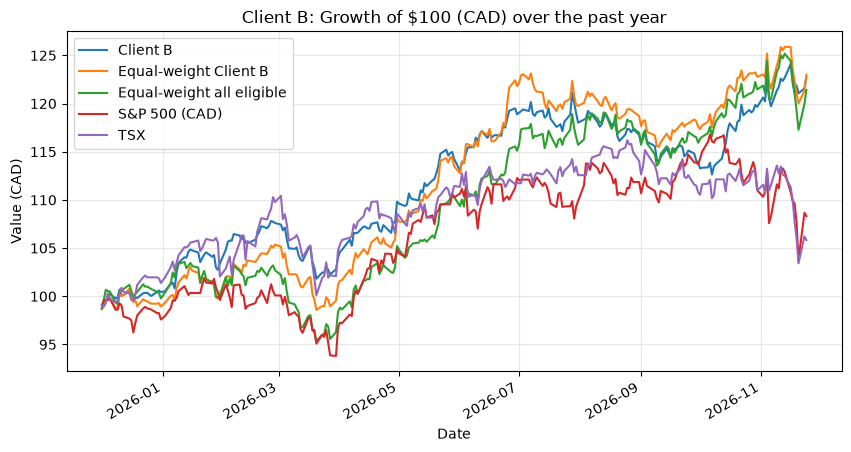

Our weighting vs equal weights on the same stocks: -0.23 percentage points of return, -1.03 points of volatility.
Our stock picks vs all eligible stocks (both equal weight): +1.58 percentage points of return, -2.28 points of volatility.


In [31]:
def performance(daily_returns):
    """Summary statistics for a Series of daily returns."""
    r = daily_returns.dropna()
    growth = (1 + r).cumprod()
    total = growth.iloc[-1] - 1
    ann_ret = (1 + total) ** (TRADING_DAYS_PER_YEAR / len(r)) - 1
    ann_vol = r.std() * np.sqrt(TRADING_DAYS_PER_YEAR)
    drawdown = (growth / growth.cummax() - 1).min()
    return pd.Series({
        "Total return (%)": total * 100,
        "Annualized return (%)": ann_ret * 100,
        "Annualized volatility (%)": ann_vol * 100,
        "Return / risk": ann_ret / ann_vol if ann_vol > 0 else np.nan,
        "Worst drop from peak (%)": drawdown * 100,
        "Best 5-day return (%)": ((1 + r).rolling(5).apply(np.prod, raw=True) - 1).max() * 100,
        "Worst 5-day return (%)": ((1 + r).rolling(5).apply(np.prod, raw=True) - 1).min() * 100,
    })

# Convert Client B's weights dict to a normalized Series
w_B = pd.Series(weights_B)
w_B = w_B / w_B.sum()

prices_B = data["prices_cad"].loc[:PURCHASE_DATE]
purchase_day = prices_B.index[-1]

# US and Canadian holidays differ: on the other market's holiday a stock's price simply did not change
window_B = prices_B.loc[:purchase_day].iloc[-(LOOKBACK_DAYS + 1):].ffill()
daily_B = window_B.pct_change().iloc[1:]

start_date = window_B.index[0] - pd.Timedelta(days=10)
end_date = window_B.index[-1] + pd.Timedelta(days=1)

sp500_usd = yf.download("^GSPC", start=start_date, end=end_date, progress=False)["Close"].squeeze()
tsx_cad = yf.download("^GSPTSE", start=start_date, end=end_date, progress=False)["Close"].squeeze()

fx = data["fx"].reindex(sp500_usd.index).ffill()

benchmarks = {
    "US": (sp500_usd * fx).ffill(),
    "CA": tsx_cad.ffill(), }

eligible_cols_B = [t for t in data["eligible"] if window_B[t].notna().all()]

comparison_returns_B = pd.DataFrame({
    "Client B": daily_B[w_B.index].mul(w_B, axis=1).sum(axis=1),
    "Equal-weight Client B": daily_B[w_B.index].mean(axis=1),
    "Equal-weight all eligible": daily_B[eligible_cols_B].mean(axis=1),
    "S&P 500 (CAD)": benchmarks["US"].reindex(window_B.index).pct_change().iloc[1:],
    "TSX": benchmarks["CA"].reindex(window_B.index).pct_change().iloc[1:],
})

comparison_table_B = comparison_returns_B.apply(performance).T.round(2)

print(f"Comparison period: {window_B.index[0].date()} to {window_B.index[-1].date()} ({len(daily_B)} trading days)")
print(f"Client B holdings: {len(w_B)} stocks")
if len(eligible_cols_B) < len(data["eligible"]):
    print("Left out of 'all eligible' (not a full year of prices):",
          sorted(set(data["eligible"]) - set(eligible_cols_B)))

display(comparison_table_B)

growth_B = (1 + comparison_returns_B.fillna(0)).cumprod() * 100
growth_B.plot(figsize=(10, 5), title="Client B: Growth of $100 (CAD) over the past year")
plt.ylabel("Value (CAD)")
plt.grid(alpha=0.3)
plt.show()

diff_B = comparison_table_B.loc["Client B"] - comparison_table_B.loc["Equal-weight Client B"]
print(f"Our weighting vs equal weights on the same stocks: {diff_B['Total return (%)']:+.2f} percentage points "
      f"of return, {diff_B['Annualized volatility (%)']:+.2f} points of volatility.")

diff2_B = comparison_table_B.loc["Equal-weight Client B"] - comparison_table_B.loc["Equal-weight all eligible"]
print(f"Our stock picks vs all eligible stocks (both equal weight): {diff2_B['Total return (%)']:+.2f} percentage points "
      f"of return, {diff2_B['Annualized volatility (%)']:+.2f} points of volatility.")

## Programmatic validation

Use Python (`assert` statements or a simple function are fine) to display whether **both** final portfolios pass each of the following checks:

- Selected tickers are valid and eligible.
- Number of stocks is between 10 and 20.
- No individual stock weight exceeds 15%.
- No single sector has more than 40% of portfolio value.
- Portfolio weights sum to 100%.
- Total stock purchases plus transaction fees do not exceed the applicable client budget.

Your code should run with the TAs’ ticker file without manually changing individual stock selections.

In [32]:
def validate_portfolio(portfolio, client, fees_cad):
    """Check a final portfolio against every rule. Returns a DataFrame of checks and prints a warning if any fail."""
    
    budget = CLIENT_BUDGETS[client]
    p = portfolio.set_index("Ticker")
    day = prices.index[-1]
    fx_day = float(data["fx"].loc[day])
    sector_w = p["Weight"].groupby(screening.loc[p.index, "Sector"]).sum()
    expected_value = p["Shares"] * p["Price"] * np.where(p["Currency"] == "USD", fx_day, 1.0)
    expected_fees = np.minimum(MAX_FEE_USD, FEE_PER_SHARE_USD * p["Shares"]).sum() * fx_day
    spent = p["Value"].sum() + fees_cad

    
    checks = [
        ("No missing values", not portfolio.isna().any().any()),
        ("No duplicate tickers", p.index.is_unique),
        ("All tickers eligible", set(p.index).issubset(data["eligible"])),
        (f"Between {MIN_STOCKS} and {MAX_STOCKS} stocks ({len(p)})", MIN_STOCKS <= len(p) <= MAX_STOCKS),
        ("All shares positive", (p["Shares"] > 0).all()),
        ("Weights add to 100%", np.isclose(p["Weight"].sum(), 1)),
        (f"Largest stock weight {p['Weight'].max():.2%} <= {MAX_STOCK_WEIGHT:.0%}",
         p["Weight"].max() <= MAX_STOCK_WEIGHT + 1e-9),
        (f"Largest sector weight {sector_w.max():.2%} <= {MAX_SECTOR_WEIGHT:.0%}",
         sector_w.max() <= MAX_SECTOR_WEIGHT + 1e-9),
        ("Value = Shares x Price x FX", np.allclose(p["Value"], expected_value, rtol=1e-6)),
        ("Weight = Value / total value", np.allclose(p["Weight"], p["Value"] / p["Value"].sum(), atol=1e-6)),
        (f"Fees match the fee rule (CAD {fees_cad:,.2f})", np.isclose(fees_cad, expected_fees, atol=0.01)),
        (f"Value + fees (CAD {spent:,.2f}) <= budget (CAD {budget:,.0f})", spent <= budget),
        (f"Budget used except CAD {budget - spent:,.2f}", budget - spent < 1),
        (f"Prices are from the purchase date ({PURCHASE_DATE.date()})", day == PURCHASE_DATE),
    ]
    
    
    result = pd.DataFrame(checks, columns=["Check", "Passed"])
    print(f"Client {client} validation:")
    print(result.to_string(index=False))
    failed = result.loc[~result["Passed"], "Check"].tolist()
    if failed:
        print("\nWARNING: failed checks:", failed)
    return result


## saving

def save_portfolio(portfolio, client):
    """Write the full portfolio table and a Ticker/Shares file for submission."""
    full_name = f"Portfolio_Final_{client}_Group_{GROUP_NUMBER}.csv"
    stocks_name = f"Stocks_Final_{client}_Group_{GROUP_NUMBER}.csv"
    portfolio.to_csv(full_name, index=False)
    portfolio[["Ticker", "Shares"]].to_csv(stocks_name, index=False)
    print("Saved", full_name, "and", stocks_name)

usdcad = float(data["fx"].loc[:PURCHASE_DATE].iloc[-1])

fees_B = 0.0
for shares in Portfolio_Final_B["Shares"]:
    fees_B += fee_cad(shares, usdcad)

if "Ticker" not in Portfolio_Final_B.columns:
    Portfolio_Final_B = Portfolio_Final_B.reset_index()
    Portfolio_Final_B.index = range(1, len(Portfolio_Final_B) + 1)

validation_B = validate_portfolio(Portfolio_Final_B, "B", fees_B)
save_portfolio(Portfolio_Final_B, "B")

# Shared files used by both clients
screening.to_csv(f"Screening_Group_{6}.csv")
comparison_table_B.to_csv(f"Comparison_B_Group_{6}.csv")
print(f"Saved Screening_Group_{6}.csv and Comparison_B_Group_{6}.csv")

Client B validation:
                                                Check  Passed
                                    No missing values    True
                                 No duplicate tickers    True
                                 All tickers eligible    True
                        Between 10 and 20 stocks (16)    True
                                  All shares positive    True
                                  Weights add to 100%    True
                   Largest stock weight 14.99% <= 15%    True
                  Largest sector weight 31.04% <= 40%    True
                          Value = Shares x Price x FX    True
                         Weight = Value / total value    True
                   Fees match the fee rule (CAD 9.82)    True
Value + fees (CAD 749,999.71) <= budget (CAD 750,000)    True
                          Budget used except CAD 0.29    True
       Prices are from the purchase date (2026-11-27)   False

Saved Portfolio_Final_B_Group_6.csv and Stocks_F

## Final portfolio outputs

Display `Portfolio_Final_A` and `Portfolio_Final_B`, along with the budget reconciliation (purchases plus fees) for each. Generate `Stocks_Group_XX_A.csv` and `Stocks_Group_XX_B.csv` (replace `XX` with your team number). Each CSV must contain **only** the columns `Ticker` and `Shares`. The notebook must **generate** these CSV files when run, but you submit **only the notebook** to Dropbox.